In [87]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import tensorflow as tf
import plotly.graph_objects as go

In [88]:
def f1(x):
    return 2*x[0]**2 + x[0]*x[1] + x[1]**2

def df1(x):
    return np.array([4*x[0] + x[1], x[0] + 2*x[1]])

def f2(x):
    return (x[1]**2 + x[0]**2 - 1)**2 + (x[0] + x[1] - 1)**2

def df2(x):
    u = x[0]**2 + x[1]**2 - 1
    v = x[0] + x[1] - 1
    return np.array([4*x[0]*u + 2*v, 4*x[1]*u + 2*v])

In [89]:
def coord_descent(f, df, x0,
                        alpha=0.1,
                        eps=1e-7,
                        max_iter=5000):

    x = np.array(x0, dtype=float)
    n = len(x)
    traj = [x.copy()]
    k = 0
    while k < max_iter:
        x_old = x.copy()
        for i in range(n):
            g = df(x)
            if abs(g[i]) < 1e-14:
                continue
            e = np.zeros(n); e[i] = 1.0
            x = x - alpha * g[i] * e
            traj.append(x.copy())
        k += 1
        if np.linalg.norm(x - x_old) < eps:
            break
    return x, f(x), k, np.array(traj)

In [ ]:
def dfp(f, df, x0,
           eps=1e-7,
           max_iter=500):
    """
    Метод DFP
        Шаг на каждой итерации — по формуле Барзилая-Борвейна BB1:
        alpha_k = (s_{k-1} . s_{k-1}) / (s_{k-1} . y_{k-1}),
    где s = x_k - x_{k-1}, y = grad_k - grad_{k-1}.
    """
    x = np.array(x0, dtype=float)
    n = len(x)
    H = np.eye(n)
    g = df(x)
    traj = [x.copy()]
    alpha = 1.0 / max(np.linalg.norm(g), 1e-12)   # начальный шаг

    k = 0
    while np.linalg.norm(g) > eps and k < max_iter:
        d = -H @ g
        if g @ d >= 0:                # потеряли свойство спуска — сброс
            d = -g
            H = np.eye(n)

        x_new = x + alpha * d
        g_new = df(x_new)
        s = x_new - x
        y = g_new - g

        if y @ s > 1e-12:
            H = H + np.outer(s, s)/(s @ y) \
                  - (H @ np.outer(y, y) @ H)/(y @ H @ y)
            alpha = (s @ s) / (s @ y)    # обновление шага по BB1
        else:
            alpha *= 0.5                 # страховка

        x = x_new
        g = g_new
        k += 1
        traj.append(x.copy())

    return x, f(x), k, np.array(traj)

In [91]:
def plot_trajectory(f, traj, title, exact=None,
                    pad=0.25, n_grid=300):
    """
    Строит линии уровня f и накладывает траекторию.
    Пределы осей и уровни изолиний подбираются автоматически:
      - xlim / ylim считаются по траектории (+ exact) с запасом pad
      - уровни изолиний — логарифмическая сетка по значениям f в окне
    """
    # --- 1. Авто-пределы по траектории ---
    all_pts = traj.copy()
    if exact is not None:
        all_pts = np.vstack([all_pts, np.array(exact)])

    x_min, x_max = all_pts[:, 0].min(), all_pts[:, 0].max()
    y_min, y_max = all_pts[:, 1].min(), all_pts[:, 1].max()

    # защита от вырожденного диапазона (все точки в одной координате)
    if x_max - x_min < 1e-6:
        x_min -= 1.0; x_max += 1.0
    if y_max - y_min < 1e-6:
        y_min -= 1.0; y_max += 1.0

    dx = (x_max - x_min) * pad
    dy = (y_max - y_min) * pad
    xlim = (x_min - dx, x_max + dx)
    ylim = (y_min - dy, y_max + dy)

    # --- 2. Сетка для линий уровня ---
    xs = np.linspace(xlim[0], xlim[1], n_grid)
    ys = np.linspace(ylim[0], ylim[1], n_grid)
    X, Y = np.meshgrid(xs, ys)
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            Z[i, j] = f(np.array([X[i, j], Y[i, j]]))

    # --- 3. Авто-уровни: логарифмическая сетка ---
    zmin = Z.min()
    zmax = Z.max()
    if zmax - zmin < 1e-12:
        levels = np.array([zmin])
    else:
        levels = np.logspace(np.log10(zmin + 1e-6),
                             np.log10(zmax), 30)

    # --- 4. Рисуем ---
    fig, ax = plt.subplots(figsize=(8, 7))
    cs = ax.contour(X, Y, Z, levels=levels,
                    cmap='viridis', linewidths=0.8)
    ax.clabel(cs, inline=True, fontsize=7, fmt='%.1e')

    ax.plot(traj[:, 0], traj[:, 1], 'r.-',
            linewidth=1.6, markersize=9, label='траектория')
    ax.plot(traj[0, 0], traj[0, 1], 'go',
            markersize=13, label='старт')
    ax.plot(traj[-1, 0], traj[-1, 1], 'b*',
            markersize=18, label='финиш')

    for i, (xi, yi) in enumerate(traj):
        ax.annotate(str(i), (xi, yi),
                    textcoords="offset points",
                    xytext=(7, 5), fontsize=8, color='darkred')

    if exact is not None:
        ax.plot(exact[0], exact[1], 'kX', markersize=14,
                label='точный минимум')

    ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')
    ax.set_title(title, fontsize=12)
    ax.set_xlim(xlim); ax.set_ylim(ylim)
    ax.grid(True, linestyle=':', alpha=0.4)
    ax.legend(loc='best', fontsize=9)
    plt.tight_layout()
    plt.show()

In [92]:
def plot_trajectory_3d_plotly(f, traj, title, exact=None,
                              pad=0.25, n_grid=100,
                              xlim=None, ylim=None, zlim=None,
                              colorscale='RdBu_r',
                              surface_opacity=0.9):
    """
    Интерактивная 3D-поверхность + траектория (plotly).
    Вращение — ЛКМ, зум — колесо, панорама — Shift+ЛКМ,
    сброс — двойной клик.
    """
    # --- 1. Пределы по осям X, Y ---
    all_pts = traj.copy()
    if exact is not None:
        all_pts = np.vstack([all_pts, np.array(exact)])

    if xlim is None:
        x_min, x_max = all_pts[:, 0].min(), all_pts[:, 0].max()
        if x_max - x_min < 1e-6:
            x_min -= 1.0; x_max += 1.0
        dx = (x_max - x_min) * pad
        xlim = (x_min - 2*dx, x_max + 2*dx)

    if ylim is None:
        y_min, y_max = all_pts[:, 1].min(), all_pts[:, 1].max()
        if y_max - y_min < 1e-6:
            y_min -= 1.0; y_max += 1.0
        dy = (y_max - y_min) * pad
        ylim = (y_min - 2*dy, y_max + 2*dy)

    # --- 2. Сетка поверхности ---
    xs = np.linspace(xlim[0], xlim[1], n_grid)
    ys = np.linspace(ylim[0], ylim[1], n_grid)
    X, Y = np.meshgrid(xs, ys)
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            Z[i, j] = f(np.array([X[i, j], Y[i, j]]))

    # --- 3. Z-диапазон для вида ---
    Ztraj = np.array([f(p) for p in traj])
    zmin = min(Z.min(), Ztraj.min())
    zmax_raw = max(Z.max(), Ztraj.max())
    zmax_cap = np.percentile(Z, 92)
    zmax = min(zmax_raw, zmax_cap)
    if zlim is not None:
        zmin, zmax = zlim

    # --- 4. Поверхность ---
    fig = go.Figure()

    fig.add_surface(
        x=X, y=Y, z=Z,
        colorscale=colorscale,
        opacity=surface_opacity,
        showscale=True,
        colorbar=dict(title='f(x)', len=0.6),
        contours={
            "z": {"show": True,
                  "usecolormap": False,
                  "highlightcolor": "black",
                  "project": {"z": True}}
        },
        name='поверхность'
    )

    # --- 5. Траектория: белая обводка + красная линия ---
    fig.add_scatter3d(
        x=traj[:, 0], y=traj[:, 1], z=Ztraj,
        mode='lines',
        line=dict(color='white', width=8),
        showlegend=False, hoverinfo='skip'
    )
    fig.add_scatter3d(
        x=traj[:, 0], y=traj[:, 1], z=Ztraj,
        mode='lines+markers+text',
        text=[str(i) for i in range(len(traj))],
        textposition='top center',
        textfont=dict(color='black', size=10),
        line=dict(color='red', width=4),
        marker=dict(size=5, color='red',
                    line=dict(color='white', width=1)),
        name='траектория'
    )

    # --- 6. Вертикальные нити ---
    for i, (xi, yi, zi) in enumerate(zip(traj[:, 0], traj[:, 1], Ztraj)):
        fig.add_scatter3d(
            x=[xi, xi], y=[yi, yi], z=[zmin, zi],
            mode='lines',
            line=dict(color='gray', width=1, dash='dot'),
            showlegend=False, hoverinfo='skip'
        )

    # --- 7. Старт / финиш / точный минимум ---
    fig.add_scatter3d(
        x=[traj[0, 0]], y=[traj[0, 1]], z=[Ztraj[0]],
        mode='markers',
        marker=dict(size=10, color='lime',
                    line=dict(color='black', width=2)),
        name='старт'
    )
    fig.add_scatter3d(
        x=[traj[-1, 0]], y=[traj[-1, 1]], z=[Ztraj[-1]],
        mode='markers',
        marker=dict(size=14, color='blue', symbol='diamond',
                    line=dict(color='white', width=2)),
        name='финиш'
    )
    if exact is not None:
        fig.add_scatter3d(
            x=[exact[0]], y=[exact[1]], z=[f(np.array(exact))],
            mode='markers',
            marker=dict(size=12, color='black', symbol='x'),
            name='точный минимум'
        )

    # --- 8. Оформление ---
    fig.update_layout(
        title=title,
        width=950, height=750,
        scene=dict(
            xaxis=dict(title='x1', range=list(xlim)),
            yaxis=dict(title='x2', range=list(ylim)),
            zaxis=dict(title='f(x)', range=[zmin, zmax]),
            aspectmode='cube',
            camera=dict(eye=dict(x=1.6, y=-1.6, z=1.0))
        ),
        legend=dict(x=0.02, y=0.98,
                    bgcolor='rgba(255,255,255,0.7)')
    )

    fig.show()

ФУНКЦИЯ 1, покоординатный спуск
Итог: x* = [-1.72966907e-07  4.07302271e-07], f* = 1.553e-13, k = 106

ФУНКЦИЯ 1, DFP
Итог: x* = [1.70933567e-08 3.75411598e-07], f* = 1.479e-13, k = 500



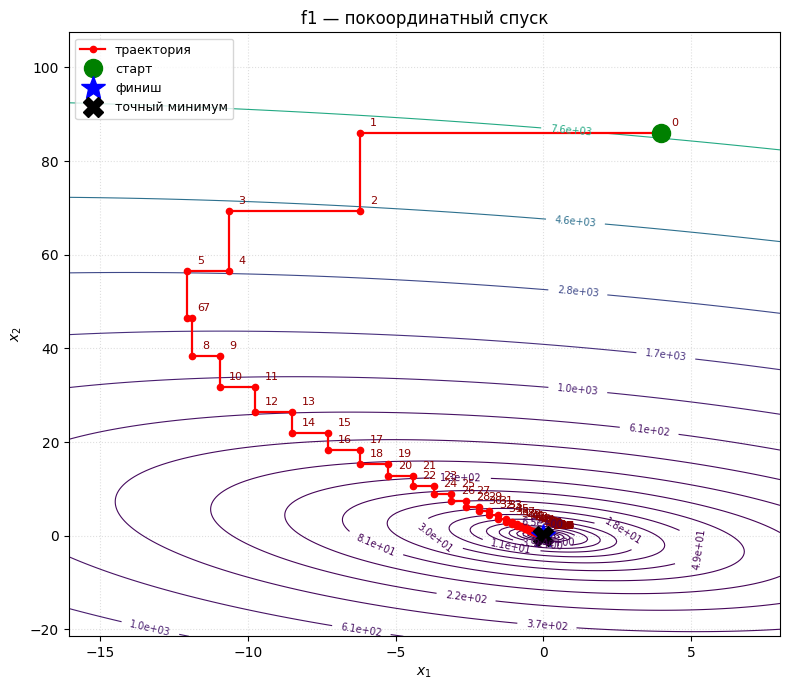

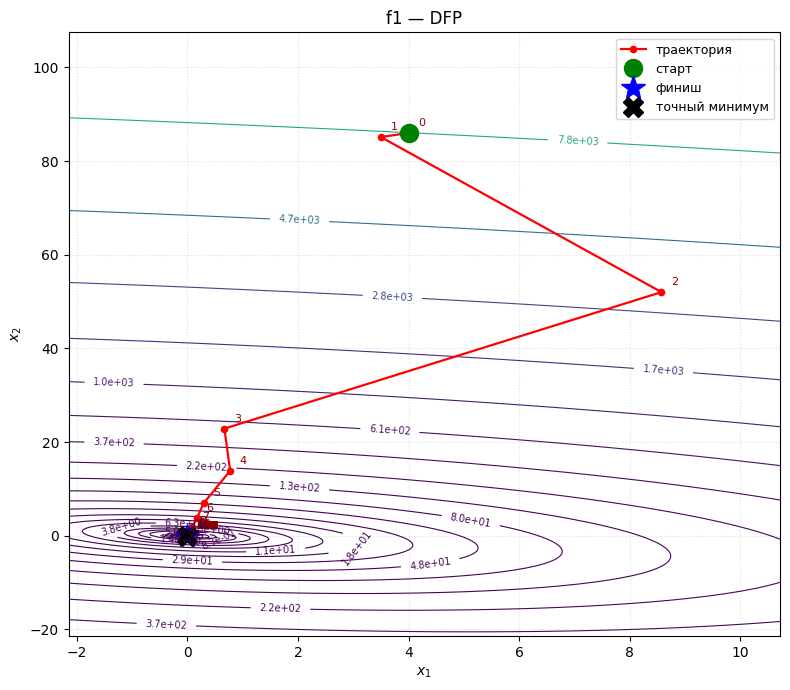

In [93]:
x0_f1 = np.array([4, 86])

print("=" * 60)
print("ФУНКЦИЯ 1, покоординатный спуск")
x_cd, f_cd, k_cd, traj_cd = coord_descent(f1, df1, x0_f1)
print(f"Итог: x* = {x_cd}, f* = {f_cd:.3e}, k = {k_cd}\n")

print("ФУНКЦИЯ 1, DFP")
x_dfp, f_dfp, k_dfp, traj_dfp = dfp(f1, df1, x0_f1)
print(f"Итог: x* = {x_dfp}, f* = {f_dfp:.3e}, k = {k_dfp}\n")

plot_trajectory(f1, traj_cd,
                title='f1 — покоординатный спуск',
                exact=(0, 0))
plot_trajectory(f1, traj_dfp,
                title='f1 — DFP',
                exact=(0, 0))

ФУНКЦИЯ 2, x0 = [2.2 1. ]
--- покоординатный спуск (α = 0.02) ---
Итог: x* = [9.99999282e-01 3.03700847e-06], f* = 7.440e-12, k = 461

--- DFP ---
Итог: x* = [1.00000018e+00 7.76648947e-07], f* = 1.034e-12, k = 500



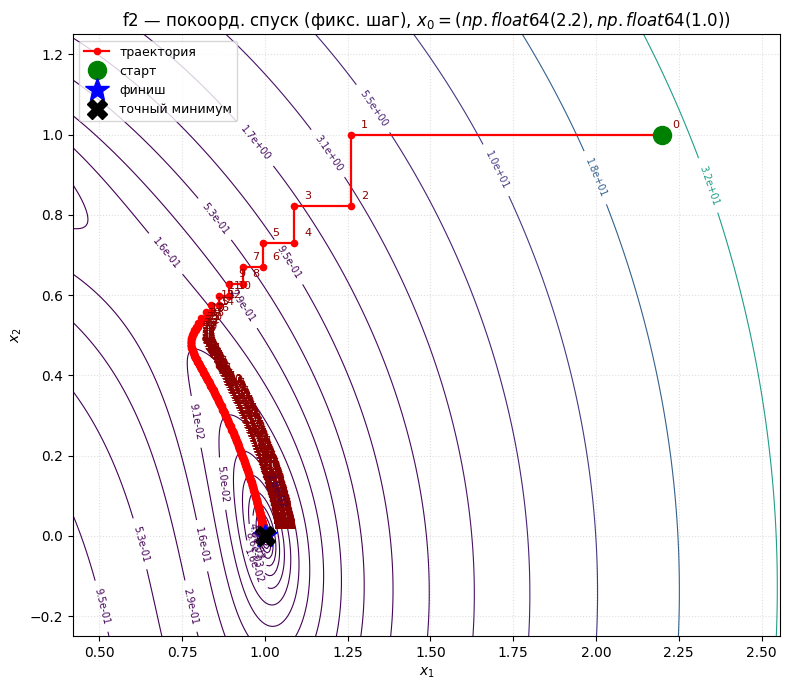

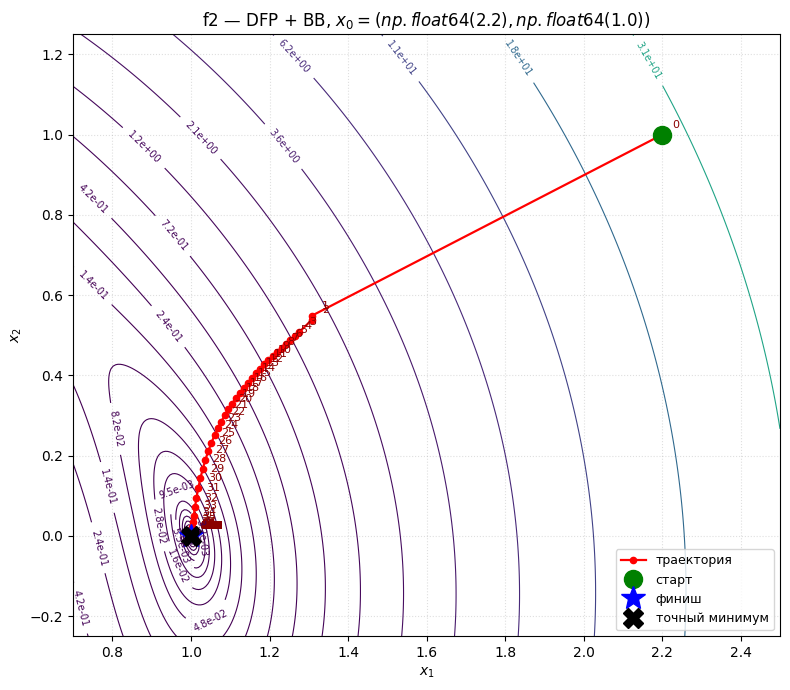

ФУНКЦИЯ 2, x0 = [1.  2.2]
--- покоординатный спуск (α = 0.02) ---
Итог: x* = [3.06054394e-06 9.99999299e-01], f* = 7.533e-12, k = 388

--- DFP ---
Итог: x* = [7.76648947e-07 1.00000018e+00], f* = 1.034e-12, k = 500



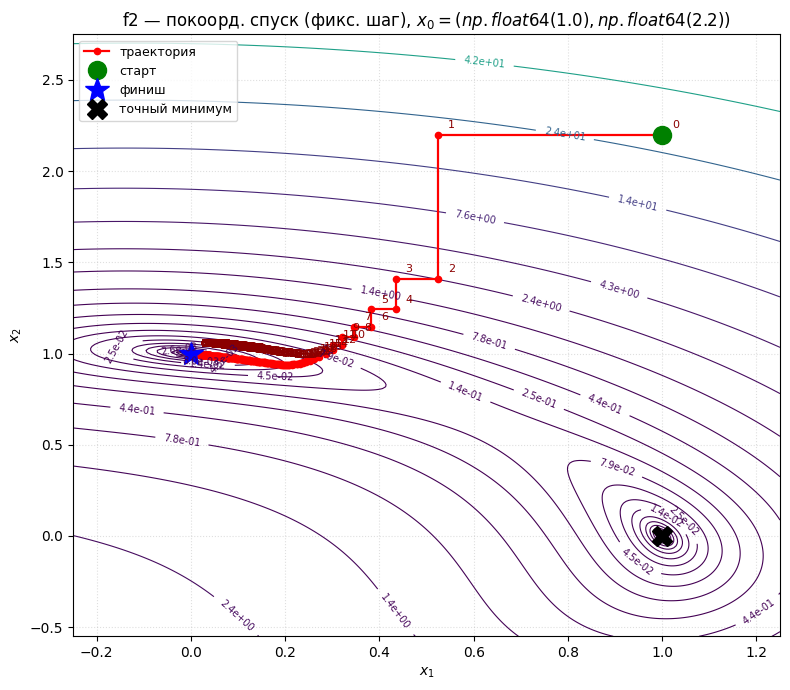

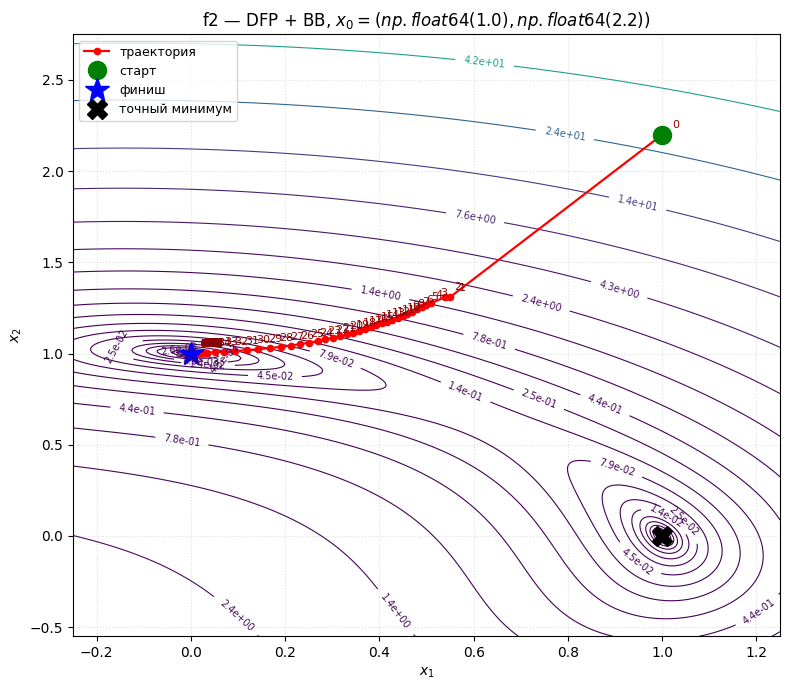

In [94]:
for x0 in [np.array([2.2, 1.0]), np.array([1, 2.2])]:
    print("=" * 60)
    print(f"ФУНКЦИЯ 2, x0 = {x0}")

    print("--- покоординатный спуск (α = 0.02) ---")
    x_cd, f_cd, k_cd, traj_cd = coord_descent(
        f2, df2, x0, alpha=0.02, max_iter=20000)
    print(f"Итог: x* = {x_cd}, f* = {f_cd:.3e}, k = {k_cd}\n")

    print("--- DFP ---")
    x_dfp, f_dfp, k_dfp, traj_dfp = dfp(f2, df2, x0)
    print(f"Итог: x* = {x_dfp}, f* = {f_dfp:.3e}, k = {k_dfp}\n")

    exact = (0, 1) if x0[0] == 0 else (1, 0)

    plot_trajectory(f2, traj_cd,
                    title=f'f2 — покоорд. спуск (фикс. шаг), $x_0={tuple(x0)}$',
                    exact=exact)
    plot_trajectory(f2, traj_dfp,
                    title=f'f2 — DFP + BB, $x_0={tuple(x0)}$',
                    exact=exact)

In [95]:
x_cd_1,  f_cd_1,  k_cd_1,  traj_cd_1  = coord_descent(f1, df1, x0_f1, alpha=0.1)
x_dfp_1, f_dfp_1, k_dfp_1, traj_dfp_1 = dfp(f1, df1, x0_f1)

In [96]:
print("=" * 60)
print("3D-ВИЗУАЛИЗАЦИЯ ФУНКЦИИ 1")

plot_trajectory_3d_plotly(f1, traj_cd_1,   # траектория покоорд. спуска для f1
                   title='f1 — покоординатный спуск (3D)',
                   exact=(0, 0), colorscale='reds')

plot_trajectory_3d_plotly(f1, traj_dfp_1,  # траектория DFP для f1
                   title='f1 — DFP (3D)',
                   exact=(0, 0), colorscale='reds')

3D-ВИЗУАЛИЗАЦИЯ ФУНКЦИИ 1


In [97]:
x_cd_2,  f_cd_2,  k_cd_2,  traj_cd_2  = coord_descent(f2, df2, np.array([0, 1]), alpha=0.1)
x_dfp_2, f_dfp_2, k_dfp_2, traj_dfp_2 = dfp(f1, df1, np.array([0, 1]))

In [ ]:
print("=" * 60)
print("3D-ВИЗУАЛИЗАЦИЯ ФУНКЦИИ 5")

for idx, x0 in enumerate([np.array([2.2, 1.0]),
                          np.array([1.0, 2.2])], start=1):
    print(f"\n--- x0 = {x0} ---")

    # покоординатный спуск
    x_cd, f_cd, k_cd, traj_cd = coord_descent(
        f2, df2, x0, alpha=0.02, max_iter=20000)
    print(f"покоорд.: x* = {x_cd}, f* = {f_cd:.3e}, k = {k_cd}")

    # DFP + BB
    x_dfp, f_dfp, k_dfp, traj_dfp = dfp(f2, df2, x0)
    print(f"DFP+BB:   x* = {x_dfp}, f* = {f_dfp:.3e}, k = {k_dfp}")

    exact = (0, 1) if x0[0] == 0 else (1, 0)

    plot_trajectory_3d_plotly(f2, traj_cd,
                       title=f'f2 — покоорд. спуск (3D), x_0={tuple(x0)}',
                       exact=exact, colorscale='reds')

    plot_trajectory_3d_plotly(f2, traj_dfp,
                       title=f'f2 — DFP + BB (3D), x_0={tuple(x0)}',
                       exact=exact, colorscale='reds')

3D-ВИЗУАЛИЗАЦИЯ ФУНКЦИИ 5

--- x0 = [2.2 1. ] ---
покоорд.: x* = [9.99999282e-01 3.03700847e-06], f* = 7.440e-12, k = 461
DFP+BB:   x* = [1.00000018e+00 7.76648947e-07], f* = 1.034e-12, k = 500



--- x0 = [1.  2.2] ---
покоорд.: x* = [3.06054394e-06 9.99999299e-01], f* = 7.533e-12, k = 388
DFP+BB:   x* = [7.76648947e-07 1.00000018e+00], f* = 1.034e-12, k = 500


: 